# A 1D diffusion model

Here we develop a one-dimensional model of diffusion.
It assumes a constant diffusivity.
It uses a regular grid.
It has a step functions for an initial porfile.
It has fixed boundary conditions.

This is diffusion equation:

$$ \frac{\partial z}{\partial t} = D\frac{\partial^2 z}{\partial x^2} $$

Here, $z$ is elevation, $t$ is time, $x$ is the spatial dimension, and $D$ is a trnasport-rate coefficeient, sometimes called hillslope diffusivity -- with dimensions length squared per time.

The discretized version of the diffusion equation of the diffusion model is:

$$ z^{t+1}_x = z^t_x + {D \Delta t \over \Delta x^2} (z^t_{x+1} - 2z^t_x + z^t_{x-1}) $$

This is the FTCS scheme that you can look up in a textbook

We'll use two libraies, NumPy (for array) and Matplotlib (for plots), that aren't a part of the core Python distribution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Start by setting two fixed model parameters -- the diffusivity and the size of the model domain.

In [4]:
D = 100  # diffusivity
Lx = 300 # model domain

Next, set up the grid using a NumPy array.

In [7]:
dx = 0.5 # grid spacing
x = np.arange(start=0, stop=Lx, step=dx)
nx = len(x)

Set the initial conditions for the mdodel.
The elevation $z$ is a step function with a high value to the left, a low value on the right, and a cliff in the middle of the domain.

In [14]:
z = np.zeros_like(x)
z_left = 500
z_right = 0
z[ :nx//2] = z_left
z[nx//2: ] = z_right

Plot the profile.

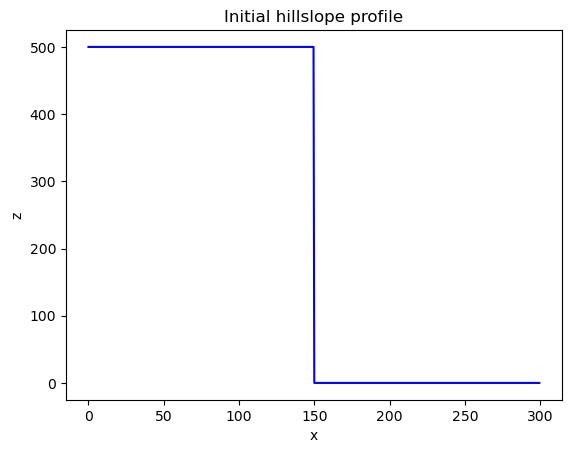

In [17]:
plt.figure()
plt.plot(x, z, "b")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Initial hillslope profile")
plt.show()

Set time stepping for the model.
Calculate a stable time step from a stability citerion.

In [19]:
nt = 5000
dt = 0.5 * dx **2 / D

Loop over the time steps of the model, solving the diffusion equation using the FTCS scheme desribed above. Note the use of array operations on the elevation z. The boundary conditions remain fixed in each time step.

In [20]:
for t in range(0, nt):
	z[1:-1] += D * dt / dx ** 2 * (z[:-2] - 2*z[1:-1] + z[2:])

Text(0.5, 1.0, 'Final hillslope profile')

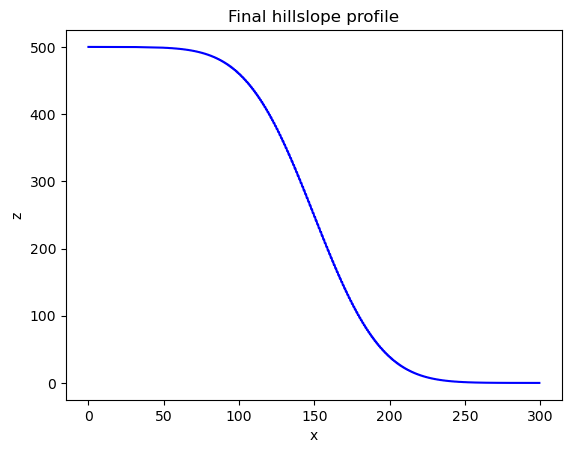

In [23]:
plt.figure()
plt.plot(x, z, "b")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Final hillslope profile")